In [1]:
import os
import sys

sys.path.append("../utils")
from data_loader import load_bill_data

from embedding_utils import extract_embeddings
from transformers import AutoTokenizer, AutoModel
from embedding_utils import extract_embeddings

import pandas as pd
import numpy as np

from scipy.stats import normaltest, kstest, anderson
import matplotlib.pyplot as plt
import seaborn as sns

from outlier_analysis_utils import detect_outliers_iqr, plot_boxplot_with_outliers, check_normality, split_url

In [2]:
fields_to_extract = {
    "bill_number": "bill_data.number",
    "bill_url": "bill_data.url",
    "bill_title": "bill_data.title",
    "sponsor_name": "sponsor.name",
    "sponsor_url": "sponsor.url",
    "summary_title": "summary.title",
    "summary_text": "summary.text",
    "source_url": "metadata.source_url",
    "view_text_url": "view_text_url",
    "download_pdf_url": "download_pdf_url",
    "is_home_rule": "is_home_rule",
    "municipality": "municipality",
    "num_cosponsors": "num_cosponsors",
    "cosponsors": "cosponsors",  
    "history": "history"
}


root_path ='../../downloaded_legislation/'
json_files = os.path.join(root_path, 'state/MA/*/*/*/*/*.json') # glob pattern for json files

df = load_bill_data(json_files, fields_to_extract, with_outlier = True)
df.head()

,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path
0,H.4147,https://malegislature.gov/Bills/192/H4147,An Act providing technical education and econo...,"Harrington, Sheila C.",https://malegislature.gov/Legislators/Profile/...,An Act providing technical education and econo...,"(a) For purposes of this act, “autism spectrum...",https://malegislature.gov/Bills/192/H4147,https://malegislature.gov/Bills/192/H4147/Hous...,https://malegislature.gov/Bills/192/H4147.pdf,False,None,3,"[{'name': 'Lindsay N. Sabadosa', 'district': '...","[{'date': '9/30/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
1,S.1263,https://malegislature.gov/Bills/192/S1263,An Act relative to recovery homes,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,An Act relative to recovery homes,Nothwithstanding any special or general law to...,https://malegislature.gov/Bills/192/S1263,https://malegislature.gov/Bills/192/S1263/Sena...,https://malegislature.gov/Bills/192/S1263.pdf,False,None,0,[],"[{'date': '3/29/2021', 'branch': 'Senate', 'ac...",../../downloaded_legislation/state/MA/192nd/20...
2,H.3682,https://malegislature.gov/Bills/192/H3682,An Act amending the Medal of Liberty,"Murray, Brian W.",https://malegislature.gov/Legislators/Profile/...,An Act amending the Medal of Liberty,"Chapter 33 Section 67A of the General Laws, as...",https://malegislature.gov/Bills/192/H3682,https://malegislature.gov/Bills/192/H3682/Hous...,https://malegislature.gov/Bills/192/H3682.pdf,False,None,7,"[{'name': 'Michael J. Soter', 'district': '8th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
3,SD.3464,https://malegislature.gov/Bills/192/SD3464,DVS Veteran Advisory Committee Interim Report,None,None,DVS Veteran Advisory Committee Interim Report,Report of the Department of Veterans’ Services...,https://malegislature.gov/Bills/192/SD3464,None,https://malegislature.gov/Bills/192/SD3464.pdf,False,None,0,[],"[{'date': '1/3/2023', 'branch': 'Senate', 'act...",../../downloaded_legislation/state/MA/192nd/20...
4,H.2990,https://malegislature.gov/Bills/192/H2990,An Act to encourage Massachusetts residency,"Livingstone, Jay D.",https://malegislature.gov/Legislators/Profile/...,An Act to encourage Massachusetts residency,SECTION 1. Chapter 65C of the General Laws is ...,https://malegislature.gov/Bills/192/H2990,https://malegislature.gov/Bills/192/H2990/Hous...,https://malegislature.gov/Bills/192/H2990.pdf,False,None,1,"[{'name': 'Carlos González', 'district': '10th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70641 entries, 0 to 70640
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   bill_number       70641 non-null  object
 1   bill_url          70641 non-null  object
 2   bill_title        70641 non-null  object
 3   sponsor_name      47629 non-null  object
 4   sponsor_url       45806 non-null  object
 5   summary_title     70641 non-null  object
 6   summary_text      70641 non-null  object
 7   source_url        70641 non-null  object
 8   view_text_url     63308 non-null  object
 9   download_pdf_url  68585 non-null  object
 10  is_home_rule      70641 non-null  bool  
 11  municipality      3995 non-null   object
 12  num_cosponsors    70641 non-null  int64 
 13  cosponsors        70641 non-null  object
 14  history           70331 non-null  object
 15  path              70641 non-null  object
dtypes: bool(1), int64(1), object(14)
memory usage: 8.2+ MB


### Data Sources

For bill text source we have 2 options:
1. `view_text_url` - which is the HTML version of the bill text
2. `download_pdf_url` - which is the PDF version of the bill text

There are some bills that have both, some that have only one of them, and some that have neither.

In [4]:
print("Number of None values in download_pdf_url:", df.download_pdf_url.isna().sum())
print("Number of None values in view_text_url:", df.view_text_url.isna().sum())


Number of None values in download_pdf_url: 2056
Number of None values in view_text_url: 7333


Records with NaN values in `download_pdf_url` are associated with invalid links in `view_text_url`:

In [5]:
invalid_view_text_url = df.view_text_url.apply(lambda x: 'invalid' in x.lower() if isinstance(x, str) else False)
(invalid_view_text_url == df.download_pdf_url.isna()).sum(), df.shape

(np.int64(70641), (70641, 16))

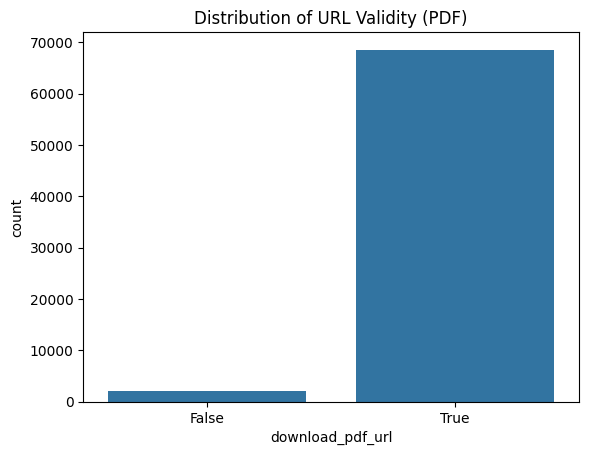

In [6]:
sns.countplot(x=df.download_pdf_url.notna())
plt.title("Distribution of URL Validity (PDF)")
plt.show()

We can remove rows with NaN values in the `download_pdf_url` column.

In [7]:
df.dropna(subset=['download_pdf_url'], inplace=True)
df.shape

(68585, 16)

In [8]:
# Even if we do not have a view_text_url data, we still have a download_pdf_url to get acces to the bill text
df[df.view_text_url.isna()].download_pdf_url.isna().sum()

np.int64(0)

Changed `data_loader.py `to skip these outliers

### Relation between Home rule and Municipality

In [9]:
df.municipality = df.municipality.apply(lambda x: x.split('\r\n')[0] if pd.notna(x) else x)
df.municipality.nunique()

336

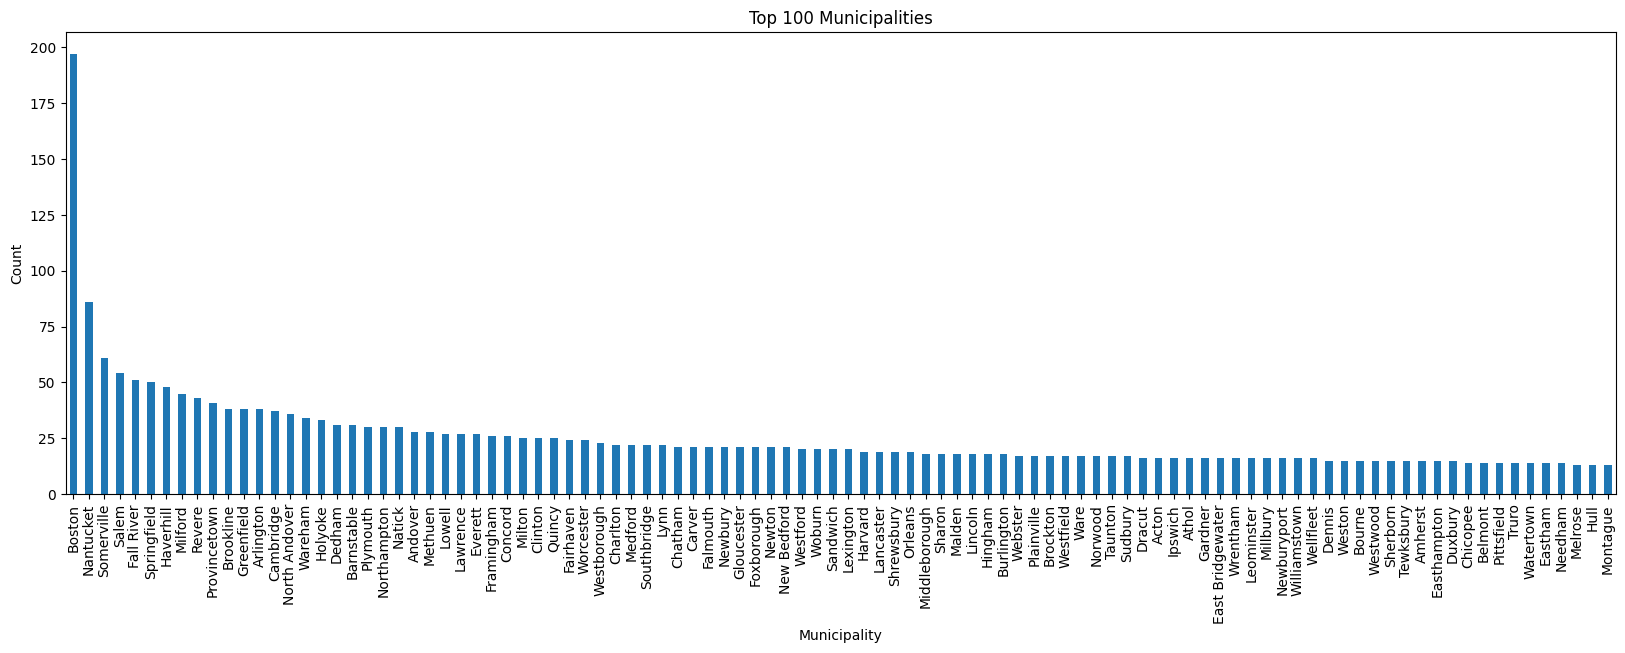

In [10]:
# plot df.municipality value counts histogram
plt.figure(figsize=(20, 6))
df['municipality'].value_counts().head(100).plot(kind='bar')
plt.title("Top 100 Municipalities")
plt.xlabel("Municipality")
plt.ylabel("Count")
plt.show()

True count: 3174
False count: 65411


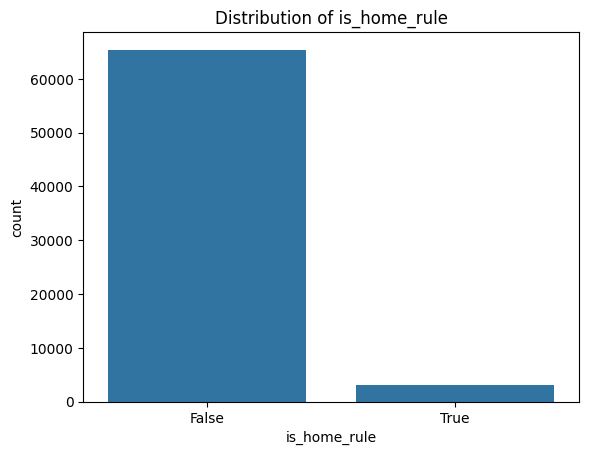

In [11]:
is_home_rule_counts = df['is_home_rule'].value_counts()
print("True count:", is_home_rule_counts.get(True, 0))
print("False count:", is_home_rule_counts.get(False, 0))

# Plotting distribution
sns.countplot(x=df['is_home_rule'])
plt.title("Distribution of is_home_rule")
plt.show()

In [12]:
# Is home rule but no data in municipality
print(df[(df.is_home_rule == True) & (df.municipality.isna())].shape)
df[(df.is_home_rule == True) & (df.municipality.isna())].head()


(34, 16)


,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path
6236,H.5139,https://malegislature.gov/Bills/192/H5139,An Act authorizing the city of Boston to grant...,"Tyler, Chynah",https://malegislature.gov/Legislators/Profile/...,An Act authorizing the city of Boston to grant...,SECTION 1.\r\n(a)\tNotwithstanding section 17 ...,https://malegislature.gov/Bills/192/H5139,https://malegislature.gov/Bills/192/H5139/Hous...,https://malegislature.gov/Bills/192/H5139.pdf,True,None,0,[],"[{'date': '7/29/2022', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
6496,HD.4472,https://malegislature.gov/Bills/192/HD4472,An Act relative to Revere and Son Heritage Tru...,"Galvin, William C.",https://malegislature.gov/Legislators/Profile/...,An Act relative to Revere and Son Heritage Tru...,SECTION 1. Subsection (d) of section 3 of chap...,https://malegislature.gov/Bills/192/HD4472,https://malegislature.gov/Bills/192/HD4472/Hou...,https://malegislature.gov/Bills/192/HD4472.pdf,True,None,1,"[{'name': 'Walter F. Timilty', 'district': 'No...","[{'date': '10/13/2021', 'branch': 'House', 'ac...",../../downloaded_legislation/state/MA/192nd/20...
8062,H.4850,https://malegislature.gov/Bills/192/H4850,An Act relative to certain affordable housing ...,"O'Day, James J.",https://malegislature.gov/Legislators/Profile/...,An Act relative to certain affordable housing ...,SECTION 1. Construction and development activi...,https://malegislature.gov/Bills/192/H4850,https://malegislature.gov/Bills/192/H4850/Hous...,https://malegislature.gov/Bills/192/H4850.pdf,True,None,0,[],"[{'date': '5/23/2022', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
8966,H.4774,https://malegislature.gov/Bills/192/H4774,An Act authorizing Thomas Harmon to purchase c...,"Xiarhos, Steven G.",https://malegislature.gov/Legislators/Profile/...,An Act authorizing Thomas Harmon to purchase c...,Notwithstanding section 3 of chapter 71 of the...,https://malegislature.gov/Bills/192/H4774,https://malegislature.gov/Bills/192/H4774/Hous...,https://malegislature.gov/Bills/192/H4774.pdf,True,None,0,[],"[{'date': '3/28/2022', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
18712,H.4366,https://malegislature.gov/Bills/191/H4366,An Act authorizing the town of Lunenburg to gr...,"Hay, Stephan",https://malegislature.gov/Legislators/Profile/...,An Act authorizing the town of Lunenburg to gr...,Section 1. (a) Notwithstanding section 17 of c...,https://malegislature.gov/Bills/191/H4366,https://malegislature.gov/Bills/191/H4366/Hous...,https://malegislature.gov/Bills/191/H4366.pdf,True,None,1,"[{'name': 'Dean A. Tran', 'district': 'Worcest...","[{'date': '2/3/2020', 'branch': 'House', 'acti...",../../downloaded_legislation/state/MA/191st/20...


In [13]:
# Not home rule but has data in municipality
print(df[(df.is_home_rule == False) & (df.municipality.notna())].shape)
df[(df.is_home_rule == False) & (df.municipality.notna())].head()

(823, 16)


,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path
160,HD.3577,https://malegislature.gov/Bills/192/HD3577,An Act relative to property tax relief for low...,"Vitolo, Tommy",https://malegislature.gov/Legislators/Profile/...,An Act relative to property tax relief for low...,Section 1. Notwithstanding section 6(k) of Cha...,https://malegislature.gov/Bills/192/HD3577,https://malegislature.gov/Bills/192/HD3577/Hou...,https://malegislature.gov/Bills/192/HD3577.pdf,False,Brookline,1,"[{'name': 'Cynthia Stone Creem', 'district': '...","[{'date': '5/27/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
265,S.1330,https://malegislature.gov/Bills/192/S1330,An Act to repeal Chapter 404 of the Acts of 2008,"DiZoglio, Diana",https://malegislature.gov/Legislators/Profile/...,An Act to repeal Chapter 404 of the Acts of 2008,Chapter 404 of the Acts of 2008 is hereby repe...,https://malegislature.gov/Bills/192/S1330,https://malegislature.gov/Bills/192/S1330/Sena...,https://malegislature.gov/Bills/192/S1330.pdf,False,North Andover,1,"[{'name': 'Bruce E. Tarr', 'district': 'First ...","[{'date': '3/29/2021', 'branch': 'Senate', 'ac...",../../downloaded_legislation/state/MA/192nd/20...
275,S.3024,https://malegislature.gov/Bills/192/S3024,An Act exempting Jesus Melendez from the maxim...,"DiZoglio, Diana",https://malegislature.gov/Legislators/Profile/...,An Act exempting Jesus Melendez from the maxim...,SECTION 1. Notwithstanding chapter 31 of the G...,https://malegislature.gov/Bills/192/S3024,https://malegislature.gov/Bills/192/S3024/Sena...,https://malegislature.gov/Bills/192/S3024.pdf,False,North Andover,3,"[{'name': 'Christina A. Minicucci', 'district'...","[{'date': '7/21/2022', 'branch': 'Senate', 'ac...",../../downloaded_legislation/state/MA/192nd/20...
399,S.2530,https://malegislature.gov/Bills/192/S2530,An Act authorizing citizens in the town of Bro...,"Creem, Cynthia Stone",https://malegislature.gov/Legislators/Profile/...,An Act authorizing citizens in the town of Bro...,SECTION 1. Notwithstanding sections 1 and 47A ...,https://malegislature.gov/Bills/192/S2530,https://malegislature.gov/Bills/192/S2530/Sena...,https://malegislature.gov/Bills/192/S2530.pdf,False,Brookline,1,"[{'name': 'Tommy Vitolo', 'district': '15th No...","[{'date': '9/13/2021', 'branch': 'Senate', 'ac...",../../downloaded_legislation/state/MA/192nd/20...
488,S.2526,https://malegislature.gov/Bills/192/S2526,An Act relative to raising the income threshol...,"Timilty, Walter F.",https://malegislature.gov/Legislators/Profile/...,An Act relative to raising the income threshol...,SECTION 1. Notwithstanding clause forty-first ...,https://malegislature.gov/Bills/192/S2526,https://malegislature.gov/Bills/192/S2526/Sena...,https://malegislature.gov/Bills/192/S2526.pdf,False,Milton,2,"[{'name': 'William J. Driscoll, Jr.', 'distric...","[{'date': '9/9/2021', 'branch': 'Senate', 'act...",../../downloaded_legislation/state/MA/192nd/20...


Corrected home_rule values in `dataset_corrections.ipynb`

### Profile data

In [14]:
sponsors = df.groupby(['sponsor_name', 'sponsor_url']).size().sort_values(ascending=False)
sponsors

sponsor_name              sponsor_url                                       
Tarr, Bruce E.            https://malegislature.gov/Legislators/Profile/BET0    1257
Creem, Cynthia Stone      https://malegislature.gov/Legislators/Profile/CSC0     750
Moore, Michael O.         https://malegislature.gov/Legislators/Profile/MOM0     601
Lewis, Jason M.           https://malegislature.gov/Legislators/Profile/jml0     595
Chan, Tackey              https://malegislature.gov/Legislators/Profile/T_C1     560
                                                                                ... 
Morrissey, Michael W.     https://malegislature.gov/Legislators/Profile/MWM0       1
Reyes, Estela A.          https://malegislature.gov/Legislators/Profile/EAR1       1
Ramos, Adrianne Pusateri  https://malegislature.gov/Legislators/Profile/APR1       1
Galluccio, Anthony D.     https://malegislature.gov/Legislators/Profile/ADG0       1
Matewsky, Wayne           https://malegislature.gov/Legislators/Profile/W

436 sponsors

In [15]:
check_normality(sponsors)

D’Agostino’s K-squared Test: Statistic = 366.9223, p-value = 0.0000
Kolmogorov-Smirnov Test: Statistic = 0.1975, p-value = 0.0000
Anderson-Darling Test: Statistic = 29.7950
  Significance level: 15.0% | Critical value: 0.571
  Significance level: 10.0% | Critical value: 0.65
  Significance level: 5.0% | Critical value: 0.78
  Significance level: 2.5% | Critical value: 0.91
  Significance level: 1.0% | Critical value: 1.082

❌ Data is likely NOT normally distributed.


For  NOT normally distributed data IQR is the best method to define outliers

IQR Outliers for Sponsors 27


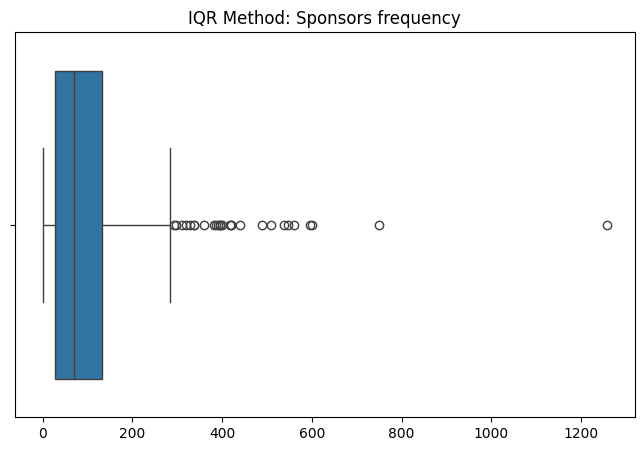

In [16]:
print('IQR Outliers for Sponsors', (detect_outliers_iqr(sponsors)).sum())
plot_boxplot_with_outliers(sponsors, title=f"IQR Method: Sponsors frequency")

In [17]:
'https://malegislature.gov/Legislators/Profile/MRP0' # 1200
'https://malegislature.gov/Legislators/Profile/BET0' # Working time > MRP0

'https://malegislature.gov/Legislators/Profile/BET0'

In [18]:
sponsors =  sponsors.reset_index()
sponsors[sponsors.sponsor_url == 'https://malegislature.gov/Legislators/Profile/MRP0']

,sponsor_name,sponsor_url,0
5,"Pacheco, Marc R.",https://malegislature.gov/Legislators/Profile/...,546


In [19]:
df['sponsor_freq'] = df.groupby(['sponsor_name', 'sponsor_url']).transform('size')
df['sponsor_label'] = df.groupby(['sponsor_name', 'sponsor_url']).ngroup()

In [20]:
sponsors['type' ] = sponsors.sponsor_url.apply(lambda url: 'committees' if 'committees' in url.lower() else 'legislator')
sponsors

,sponsor_name,sponsor_url,0,type
0,"Tarr, Bruce E.",https://malegislature.gov/Legislators/Profile/...,1257,legislator
1,"Creem, Cynthia Stone",https://malegislature.gov/Legislators/Profile/...,750,legislator
2,"Moore, Michael O.",https://malegislature.gov/Legislators/Profile/...,601,legislator
3,"Lewis, Jason M.",https://malegislature.gov/Legislators/Profile/...,595,legislator
4,"Chan, Tackey",https://malegislature.gov/Legislators/Profile/...,560,legislator
...,...,...,...,...
431,"Morrissey, Michael W.",https://malegislature.gov/Legislators/Profile/...,1,legislator
432,"Reyes, Estela A.",https://malegislature.gov/Legislators/Profile/...,1,legislator
433,"Ramos, Adrianne Pusateri",https://malegislature.gov/Legislators/Profile/...,1,legislator
434,"Galluccio, Anthony D.",https://malegislature.gov/Legislators/Profile/...,1,legislator


In [27]:
sponsors.sponsor_url.apply(lambda url: url.split('/')[3]).unique()

array(['Legislators'], dtype=object)

In [21]:

sponsors.type.value_counts()

type
legislator    436
Name: count, dtype: int64

All sponsors are legislators

### Numeric data

In [10]:
df['history_data_length'] = df.history.apply(lambda x: len(x) if isinstance(x, list) else 0)

for field in ['history_data_length', 'num_cosponsors']:
    check_normality(df[field])
    print()

D’Agostino’s K-squared Test: Statistic = 26779.0133, p-value = 0.0000
Kolmogorov-Smirnov Test: Statistic = 0.2465, p-value = 0.0000
Anderson-Darling Test: Statistic = 4974.6587
  Significance level: 15.0% | Critical value: 0.576
  Significance level: 10.0% | Critical value: 0.656
  Significance level: 5.0% | Critical value: 0.787
  Significance level: 2.5% | Critical value: 0.918
  Significance level: 1.0% | Critical value: 1.092

❌ Data is likely NOT normally distributed.

D’Agostino’s K-squared Test: Statistic = 67614.5080, p-value = 0.0000
Kolmogorov-Smirnov Test: Statistic = 0.3395, p-value = 0.0000
Anderson-Darling Test: Statistic = 12255.1503
  Significance level: 15.0% | Critical value: 0.576
  Significance level: 10.0% | Critical value: 0.656
  Significance level: 5.0% | Critical value: 0.787
  Significance level: 2.5% | Critical value: 0.918
  Significance level: 1.0% | Critical value: 1.092

❌ Data is likely NOT normally distributed.



In [15]:
df.shape

(68585, 17)

In [19]:
df.history.apply(lambda x: x[-1]['action'] if isinstance(x, list) else 0).value_counts()[:30]

history
No further action taken                                                                        11571
Placed on file                                                                                  4523
Bill reported favorably by committee and referred to the committee on House Ways and Means       870
Senate concurred                                                                                 618
Addenda                                                                                          585
Bill reported favorably by committee and referred to the committee on Senate Ways and Means      564
Accompanied a study order, see H4364                                                             535
Accompanied a study order, see H4218                                                             496
Accompanied a study order, see H5081                                                             473
No further action                                                                  

Since columns are not normally distributed, we will use the IQR. 

Outliers in history_data_length:
9598


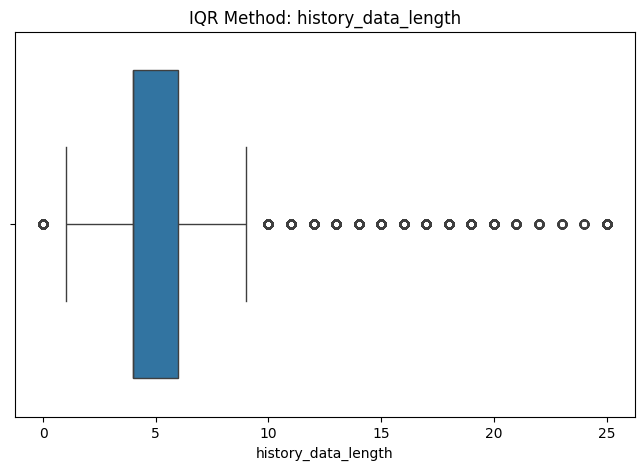

Outliers in num_cosponsors:
10512


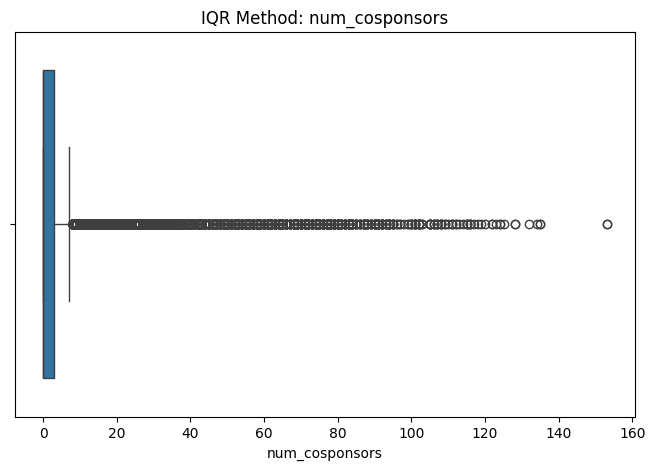

In [29]:
for field in ['history_data_length', 'num_cosponsors']:
    print(f"Outliers in {field}:")
    df[f'{field}_outliers'] = detect_outliers_iqr(df[field])
    print(sum(df[f'{field}_outliers']) )
    plot_boxplot_with_outliers(df[field], title=f"IQR Method: {field}")


Some bills have an unusually large number of cosponsors or extensive history data, which requires further analysis.

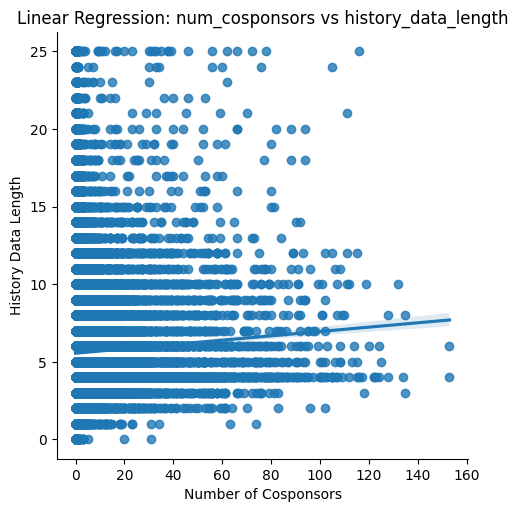

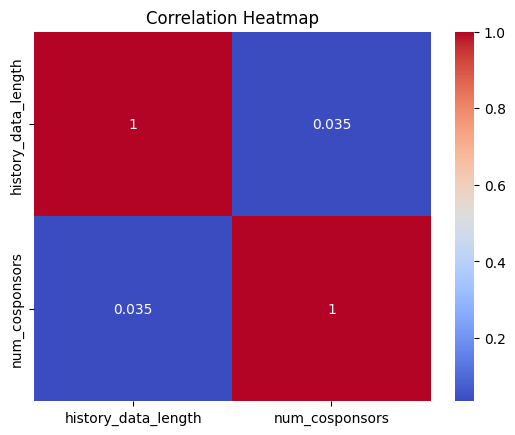

In [30]:
# RELATIONSHIP BETWEEN num_cosponsors AND history_data_length
# num_cosponsors vs history_data_length linearity
sns.lmplot(data=df, x='num_cosponsors', y='history_data_length')
plt.title("Linear Regression: num_cosponsors vs history_data_length")
plt.xlabel("Number of Cosponsors")
plt.ylabel("History Data Length")
plt.show()


# correlation
correlation = df[['history_data_length', 'num_cosponsors']].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

The analysis suggests that `num_cosponsors` and `history_data_length` are not strongly dependent on each other.

### Analysis of cosponsors

In [31]:
df[df.num_cosponsors>100].iloc[0].cosponsors

[{'name': 'Mathew J. Muratore',
  'district': '1st Plymouth',
  'url': 'https://malegislature.gov/Legislators/Profile/MJM2/192/Cosponsor'},
 {'name': 'Bruce J. Ayers',
  'district': '1st Norfolk',
  'url': 'https://malegislature.gov/Legislators/Profile/BJA1/192/Cosponsor'},
 {'name': 'Peter Capano',
  'district': '11th Essex',
  'url': 'https://malegislature.gov/Legislators/Profile/PLC1/192/Cosponsor'},
 {'name': 'John J. Lawn, Jr.',
  'district': '10th Middlesex',
  'url': 'https://malegislature.gov/Legislators/Profile/JJL2/192/Cosponsor'},
 {'name': 'Lindsay N. Sabadosa',
  'district': '1st Hampshire',
  'url': 'https://malegislature.gov/Legislators/Profile/L_S1/192/Cosponsor'},
 {'name': 'Jessica Ann Giannino',
  'district': '16th Suffolk',
  'url': 'https://malegislature.gov/Legislators/Profile/JAG1/192/Cosponsor'},
 {'name': 'Michael P. Kushmerek',
  'district': '3rd Worcester',
  'url': 'https://malegislature.gov/Legislators/Profile/MPK1/192/Cosponsor'},
 {'name': 'Steven C. Owen

Some of cosponsors do not have districet info. We will fill them using ```rocessed_legislators.csv```

In [32]:
# Test cases
url1 = 'https://malegislature.gov/Legislators/Profile/RJR1/186/Cosponsor'
url2 = 'https://malegislature.gov/Committees/Detail/J27/192/Cosponsor/H4805'
url3 = 'https://malegislature.gov/Legislators/Profile/L%20M0/193/Cosponsor'

result1 = split_url(url1)
result2 = split_url(url2)
result3 = split_url(url3)

print("Result 1:", result1)
print("Result 2:", result2)
print("Result 3:", result3)


Result 1: ('https://malegislature.gov/Legislators/Profile/RJR1', '/186/Cosponsor')
Result 2: ('https://malegislature.gov/Committees/Detail/J27', '/192/Cosponsor/H4805')
Result 3: ('https://malegislature.gov/Legislators/Profile/L%20M0', '/193/Cosponsor')


In [33]:
all_cosponsors = []

for cosponsors in df.cosponsors:
    if isinstance(cosponsors, list):
        for cosponsor in cosponsors:
            url = split_url(cosponsor['url'])[0]
            all_cosponsors.append({
                "cosponsor_name": cosponsor['name'],
                "cosponsor_url": url ,
                "cosponsor_district": cosponsor['district'],
                "type": 'committees' if 'committees' in url.lower() else 'legislator',
            })
        # all_cosponsors.extend(cosponsors)
cosponsors_df = pd.DataFrame((all_cosponsors))
# cosponsors_df = cosponsors_df.drop_duplicates()
cosponsors_df

,cosponsor_name,cosponsor_url,cosponsor_district,type
0,Lindsay N. Sabadosa,https://malegislature.gov/Legislators/Profile/...,1st Hampshire,legislator
1,Mathew J. Muratore,https://malegislature.gov/Legislators/Profile/...,1st Plymouth,legislator
2,Michael J. Soter,https://malegislature.gov/Legislators/Profile/...,8th Worcester,legislator
3,Michael J. Soter,https://malegislature.gov/Legislators/Profile/...,8th Worcester,legislator
4,Jeffrey N. Roy,https://malegislature.gov/Legislators/Profile/...,10th Norfolk,legislator
...,...,...,...,...
284598,Steven Ultrino,https://malegislature.gov/Legislators/Profile/...,33rd Middlesex,legislator
284599,James M. Murphy,https://malegislature.gov/Legislators/Profile/...,4th Norfolk,legislator
284600,Chris Walsh,https://malegislature.gov/Legislators/Profile/...,6th Middlesex,legislator
284601,Gailanne M. Cariddi,https://malegislature.gov/Legislators/Profile/...,1st Berkshire,legislator


In [34]:
cosponsors_df['type'].value_counts()

type
legislator    284528
committees        75
Name: count, dtype: int64

In [38]:
cosponsors_df[cosponsors_df.cosponsor_url=='https://malegislature.gov/Legislators/Profile/MRP0'].drop_duplicates()

,cosponsor_name,cosponsor_url,cosponsor_district,type
1164,Marc R. Pacheco,https://malegislature.gov/Legislators/Profile/...,First Plymouth and Bristol,legislator
149223,Marc R. Pacheco,https://malegislature.gov/Legislators/Profile/...,Third Bristol and Plymouth,legislator
186674,Marc R. Pacheco,https://malegislature.gov/Legislators/Profile/...,,legislator


,cosponsor_name,cosponsor_url,cosponsor_district,type
1164,Marc R. Pacheco,https://malegislature.gov/Legislators/Profile/...,First Plymouth and Bristol,legislator
149223,Marc R. Pacheco,https://malegislature.gov/Legislators/Profile/...,Third Bristol and Plymouth,legislator
186674,Marc R. Pacheco,https://malegislature.gov/Legislators/Profile/...,,legislator


### Sponsors' influence

In [24]:
df.groupby(['sponsor_name', 'sponsor_url']).size().sort_values(ascending=False)

sponsor_name              sponsor_url                                       
Tarr, Bruce E.            https://malegislature.gov/Legislators/Profile/BET0    1257
Creem, Cynthia Stone      https://malegislature.gov/Legislators/Profile/CSC0     750
Moore, Michael O.         https://malegislature.gov/Legislators/Profile/MOM0     601
Lewis, Jason M.           https://malegislature.gov/Legislators/Profile/jml0     595
Chan, Tackey              https://malegislature.gov/Legislators/Profile/T_C1     560
                                                                                ... 
Morrissey, Michael W.     https://malegislature.gov/Legislators/Profile/MWM0       1
Reyes, Estela A.          https://malegislature.gov/Legislators/Profile/EAR1       1
Ramos, Adrianne Pusateri  https://malegislature.gov/Legislators/Profile/APR1       1
Galluccio, Anthony D.     https://malegislature.gov/Legislators/Profile/ADG0       1
Matewsky, Wayne           https://malegislature.gov/Legislators/Profile/W

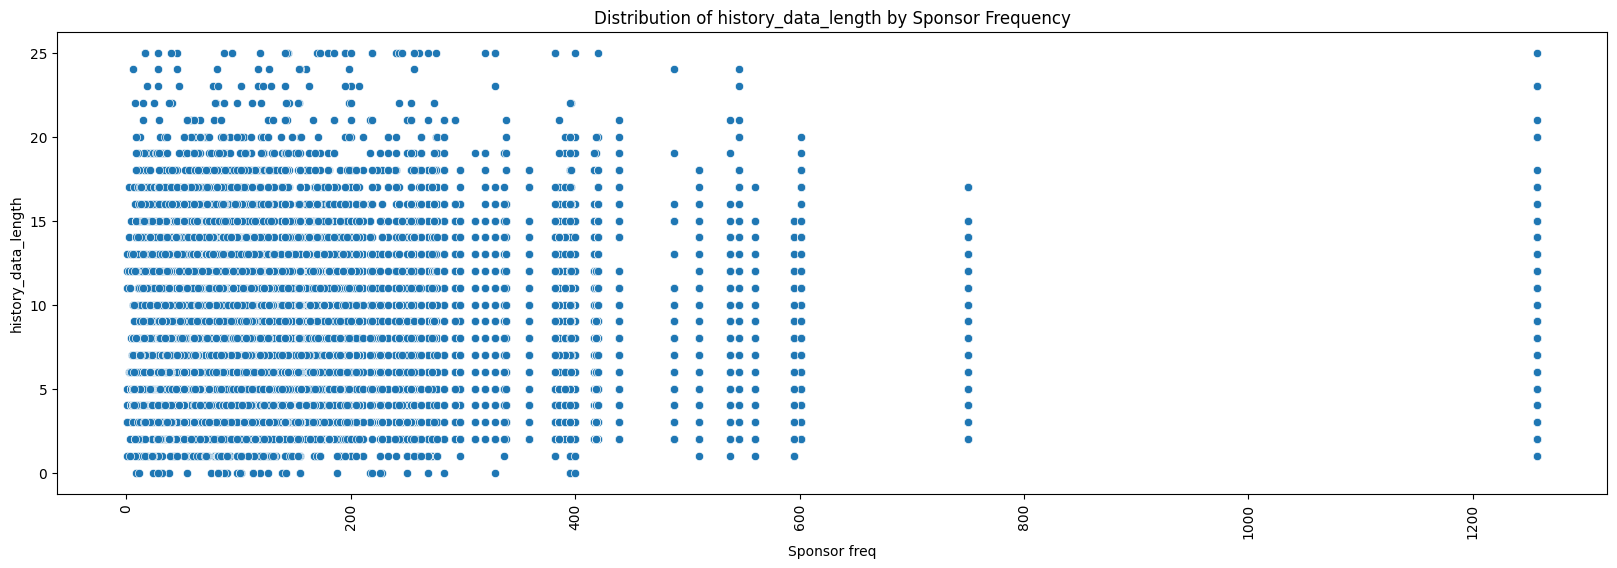

In [72]:
# RELATIONSHIP BETWEEN SPONSORS AND history_data_length
plt.figure(figsize=(20, 6))
sns.scatterplot(data=df, x='sponsor_freq', y='history_data_length')
plt.xticks(rotation=90)
plt.xlabel('Sponsor freq')
plt.title('Distribution of history_data_length by Sponsor Frequency')
plt.show()


# plt.figure(figsize=(20, 8))
# sns.boxplot(x='sponsor_label', y='history_data_length', data=df)
# plt.xticks(rotation=90)
# plt.title('Distribution of history_data_length by Sponsor Group')
# plt.show()



# from scipy.stats import kruskal

# # Create a list of history_data_length for each unique group label
# grouped_data = [group['num_cosponsors'].values for name, group in df.groupby('sponsor_label')]


# kruskal_result = kruskal(*grouped_data)
# print(f"Kruskal-Wallis H-statistic: {kruskal_result.statistic}, p-value: {kruskal_result.pvalue}")
# if kruskal_result.pvalue < 0.05:
#     print("Reject the null hypothesis: There are significant differences between groups.")
# else:   
#     print("Fail to reject the null hypothesis: No significant differences between groups.")


Sponsors that appear frequently tend to have a lower and more consistent history_data_length. Except outlier 1200

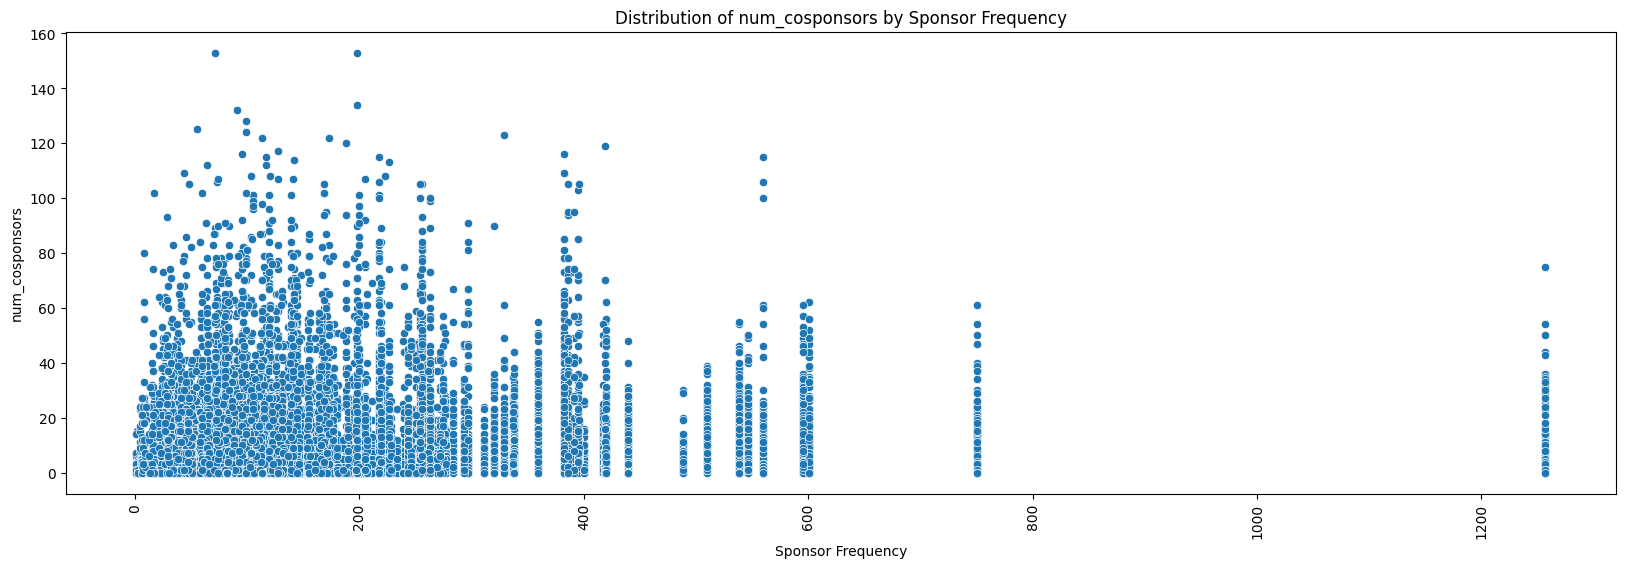

In [73]:
plt.figure(figsize=(20, 6))
sns.scatterplot(data=df, x='sponsor_freq', y='num_cosponsors')
plt.xticks(rotation=90)
plt.xlabel('Sponsor Frequency')
plt.title('Distribution of num_cosponsors by Sponsor Frequency')
plt.show()

There might be a trade-off: More frequent sponsors appear to attract fewer cosponsors per bill on average.

In [79]:
combined_metrics = df.groupby(['sponsor_name', 'sponsor_url']).agg({
    'num_cosponsors': 'mean',
    'sponsor_freq': 'size',
    'history_data_length': 'mean'
}).reset_index()

# Normalizing data for combination
combined_metrics['cosponsor_score'] = combined_metrics['num_cosponsors'] / combined_metrics['num_cosponsors'].max()
combined_metrics['freq_score'] = combined_metrics['sponsor_freq'] / combined_metrics['sponsor_freq'].max()
combined_metrics['history_score'] = combined_metrics['history_data_length'] / combined_metrics['history_data_length'].max()

# Weighted scoring system (NEED to adjust the weights)
combined_metrics['overall_influence'] = (combined_metrics['cosponsor_score'] * 0.33 +
                                         combined_metrics['freq_score'] * 0.33 +
                                         combined_metrics['history_score'] * 0.33)

# Sorting by overall influence
influential_sponsors_combined = combined_metrics.sort_values(by='overall_influence', ascending=False)

influential_sponsors_combined

,sponsor_name,sponsor_url,num_cosponsors,sponsor_freq,history_data_length,cosponsor_score,freq_score,history_score,overall_influence
384,"Tarr, Bruce E.",https://malegislature.gov/Legislators/Profile/...,2.451074,1257,5.435959,0.089948,1.000000,0.367847,0.481072
282,"Moran, John Francis",https://malegislature.gov/Legislators/Profile/...,14.000000,1,13.000000,0.513761,0.000796,0.879699,0.460105
260,"Matias, Juana B.",https://malegislature.gov/Legislators/Profile/...,27.250000,8,4.250000,1.000000,0.006364,0.287594,0.427006
92,"DeLeo, Robert A.",https://malegislature.gov/Legislators/Profile/...,8.411765,17,13.941176,0.308689,0.013524,0.943388,0.417648
201,"Jones, Bradley H.",https://malegislature.gov/Legislators/Profile/...,12.982353,510,5.558824,0.476417,0.405728,0.376161,0.415241
...,...,...,...,...,...,...,...,...,...
317,"Pease, Kelly W.",https://malegislature.gov/Legislators/Profile/...,1.142857,7,4.142857,0.041940,0.005569,0.280344,0.108191
265,"Menard, Joan M.",https://malegislature.gov/Legislators/Profile/...,0.750000,4,4.250000,0.027523,0.003182,0.287594,0.105039
405,"Vaughn, Marcus S.",https://malegislature.gov/Legislators/Profile/...,0.329268,82,3.560976,0.012083,0.065235,0.240968,0.105034
388,"Tisei, Richard R.",https://malegislature.gov/Legislators/Profile/...,4.000000,1,1.000000,0.146789,0.000796,0.067669,0.071034


In [ ]:
# sponsor_name